# NSCLC: pseudobulk DE of epithelial cells by immune infiltration

Input: `data/nsclc_integrated_annotated.rds` from `integration_annotation.ipynb` (raw counts, `sample`, `dataset`, `cell_type`).

**Why pseudobulk?** Cells of one sample are not independent replicates (same donor, dissociation and capture). Testing cell against cell treats thousands of cells as replicates and gives many false positives. Summing the counts of one cell type per sample gives **one profile per biological replicate**, which bulk RNA-seq methods (**DESeq2**) test against the variation **between samples** (Squair *et al.*, 2021).

**Which sample classes do we have?** No clinical table comes with the data. The 10x NSCLC_7pt set (P1–P4) has no clinical annotation. GSE148071 (Wu *et al.*, 2021, treatment-naive advanced NSCLC biopsies) has histology and stage in its supplementary table, but they are not in our object. The only classes we have for sure are:

| Class | Levels | Usable for DE? |
|---|---|---|
| `dataset` | NSCLC_7pt vs GSE148071 | no: study, lab, protocol and patients all change together (it is a **batch**, used as a covariate) |
| `sample` | 8 donors | the replicate unit, not a class |
| **immune infiltration** (derived here) | high vs low fraction of immune cells | **yes, as a demonstration** (see the caveats in A) |

Steps:
1. **A.** Immune fraction per sample → a dummy class `infiltration` (high / low)
2. **B.** Epithelial pseudobulk per sample
3. **C.** Pseudobulk QC: size filters, gene filtering, normalisation, MDS/PCA, sample correlations, covariates of the main PCs, ambient RNA
4. **D.** DESeq2: epithelial cells of high vs low infiltration tumours, `~ dataset + infiltration`, with post-fit checks

**Output:** tables in `data/tables/NSCLC_pseudobulk/`.

## 0. Setup

In [1]:
suppressPackageStartupMessages({
  library(Seurat)
  library(ggplot2)
  library(patchwork)
  library(BiocParallel)
})
options(repr.plot.width = 12, repr.plot.height = 6)
stage_times <- c(Setup = Sys.time())

# Paths: Jupyter runs the notebook in scripts/seurat_analysis/, so the project root is two folders up
base_dir <- normalizePath(file.path(getwd(), "..", ".."))
if (!file.exists(file.path(base_dir, "install.sh"))) stop("Open this notebook from scripts/seurat_analysis/ (project root not found)")
input_rds <- file.path(base_dir, "data", "nsclc_integrated_annotated.rds")
table_dir <- file.path(base_dir, "data", "tables", "NSCLC_pseudobulk")
dir.create(table_dir, recursive = TRUE, showWarnings = FALSE)

# Parameters
seed             <- 198716
epi_label        <- "Epithelial_cells"   # SingleR (HPCA) label of the cells we test
immune_labels    <- c("T_cells", "NK_cell", "B_cell", "Pre-B_cell_CD34-", "Pro-B_cell_CD34+",
                      "Monocyte", "Macrophage", "DC", "Neutrophils")   # HPCA labels counted as immune
infiltration_cut <- 0.5      # immune fraction >= this -> "high" infiltration
min_cells        <- 20       # a pseudobulk needs >= this many epithelial cells
min_lib          <- 1e5      # ... and >= this many counts in total
fdr              <- 0.05     # adjusted p-value cut-off
min_lfc          <- 1        # |shrunken log2 fold change| cut-off for a DEG
set.seed(seed)
BiocParallel::register(MulticoreParam(workers = 6))

## A. Sample classes: immune infiltration

**Immune fraction** = immune cells / all QC-passed cells of a sample, from the `cell_type` labels. The fraction of *PTPRC* (CD45)-expressing cells is shown as an independent check that does not depend on the annotation. Samples with an immune fraction ≥ `infiltration_cut` are coded **high**, the others **low**: a dummy (0/1) variable that DESeq2 uses as `infiltrationhigh`.

In [2]:
stage_times["A. Sample classes"] <- Sys.time()
nsclc <- readRDS(input_rds)
table(nsclc$cell_type, nsclc$sample)
samples_7pt <- unique(as.character(nsclc$sample[nsclc$dataset == "NSCLC_7pt"]))
intersect(immune_labels, unique(nsclc$cell_type))     # immune labels present in this object

nsclc$is_immune <- nsclc$cell_type %in% immune_labels
immune_frac <- tapply(nsclc$is_immune, as.character(nsclc$sample), mean)
ptprc_frac  <- tapply(FetchData(nsclc, vars = "PTPRC", layer = "counts")[, 1] > 0, as.character(nsclc$sample), mean)

sample_info <- data.frame(
  row.names   = names(immune_frac),
  sample      = names(immune_frac),
  dataset     = ifelse(names(immune_frac) %in% samples_7pt, "NSCLC_7pt", "GSE148071"),
  n_cells_all = as.vector(table(as.character(nsclc$sample))[names(immune_frac)]),
  immune_frac = round(as.vector(immune_frac), 3),
  ptprc_frac  = round(as.vector(ptprc_frac[names(immune_frac)]), 3)
)
sample_info$infiltration <- factor(ifelse(sample_info$immune_frac >= infiltration_cut, "high", "low"),
                                   levels = c("low", "high"))
sample_info[order(sample_info$immune_frac), ]
table(sample_info$dataset, sample_info$infiltration)
write.csv(sample_info, file.path(table_dir, "sample_immune_infiltration.csv"), row.names = FALSE)

                   
                      P1   P2   P3   P4 GSE148071_P1 GSE148071_P3 GSE148071_P7
  B_cell             131  148  180  409          183           16          898
  Endothelial_cells    2    0    4   12          120            9            6
  Epithelial_cells   522    6   85  120         3672         7175          230
  Fibroblasts         45   54   19   17          235           34           53
  Monocyte           151  131  290  185          698           83          636
  Neurons              3  775    1    4            0            0            0
  T_cells            508  403  316  191           41           12         1045
                   
                    GSE148071_P10
  B_cell                       98
  Endothelial_cells            40
  Epithelial_cells           2505
  Fibroblasts                 535
  Monocyte                    305
  Neurons                       0
  T_cells                      49

[1] "T_cells"  "B_cell"   "Monocyte"

,sample,dataset,n_cells_all,immune_frac,ptprc_frac,infiltration
,<chr>,<chr>,<int>,<dbl>,<dbl>,<fct>
GSE148071_P3,GSE148071_P3,GSE148071,7329,0.015,0.015,low
GSE148071_P10,GSE148071_P10,GSE148071,3532,0.128,0.133,low
GSE148071_P1,GSE148071_P1,GSE148071,4949,0.186,0.200,low
P2,P2,NSCLC_7pt,1517,0.450,0.457,low
P1,P1,NSCLC_7pt,1362,0.580,0.530,high
P4,P4,NSCLC_7pt,938,0.837,0.657,high
P3,P3,NSCLC_7pt,895,0.878,0.734,high
GSE148071_P7,GSE148071_P7,GSE148071,2868,0.899,0.563,high


           
            low high
  GSE148071   3    1
  NSCLC_7pt   1    3

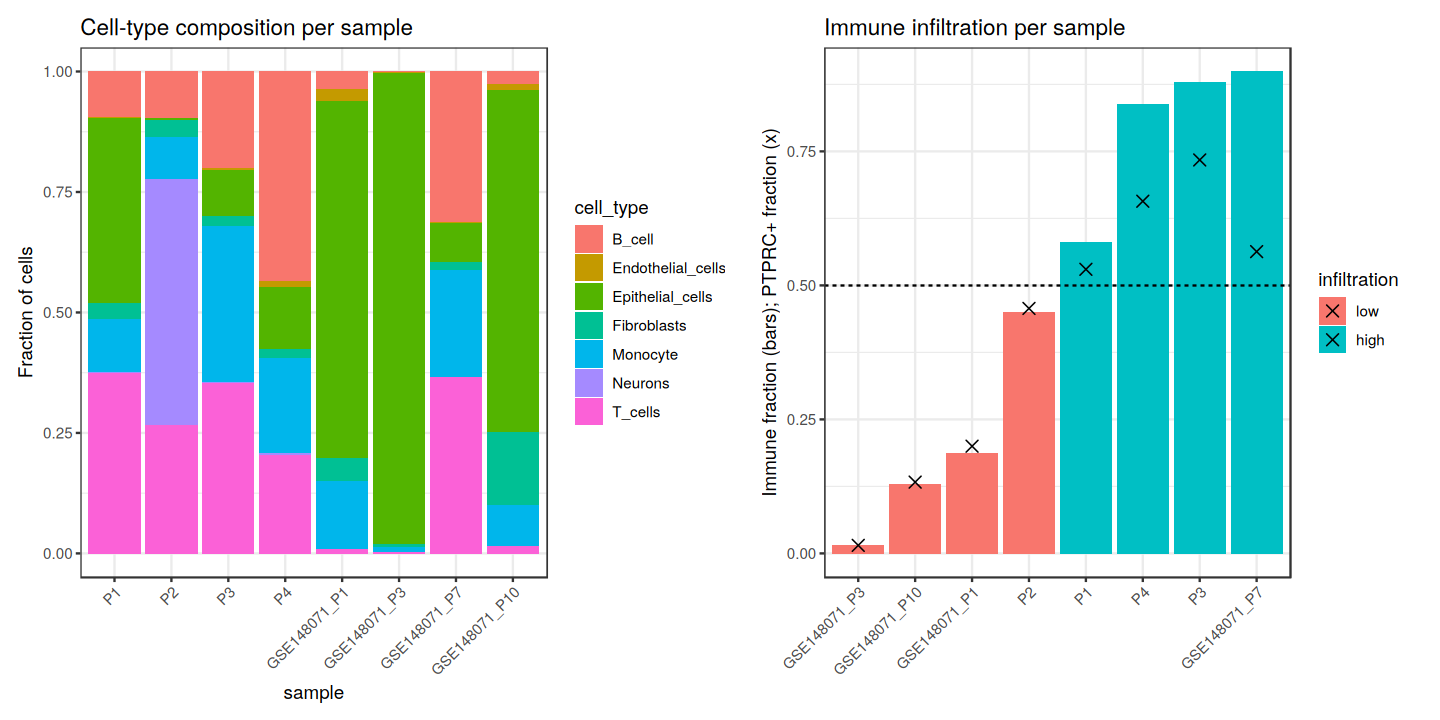

In [3]:
p1 <- ggplot(nsclc@meta.data, aes(sample, fill = cell_type)) + geom_bar(position = "fill") +
      theme_bw() + RotatedAxis() + labs(y = "Fraction of cells", title = "Cell-type composition per sample")
p2 <- ggplot(sample_info, aes(reorder(sample, immune_frac), immune_frac, fill = infiltration)) + geom_col() +
      geom_point(aes(y = ptprc_frac), shape = 4, size = 3) +
      geom_hline(yintercept = infiltration_cut, linetype = 2) + theme_bw() + RotatedAxis() +
      labs(x = NULL, y = "Immune fraction (bars); PTPRC+ fraction (x)", title = "Immune infiltration per sample")
print(p1 + p2)

**Alternative grouping: composition clusters.** Samples can also be grouped by clustering their whole cell-type composition (no clinical meaning, a data-driven class). Two choices make it robust:
- **proportions, not counts**, transformed with the centred log-ratio (CLR): log counts also reflect how many cells a sample has (GSE148071 samples have 3–7× more cells);
- **only cell types shared by several samples**: a donor-specific cluster (P2's "Neurons"/"iPS_cells") would otherwise split that donor off on its own.

[1] "B_cell"           "Epithelial_cells" "Fibroblasts"      "Monocyte"        
[5] "T_cells"

            composition
infiltration C1 C2
        low   3  1
        high  0  4

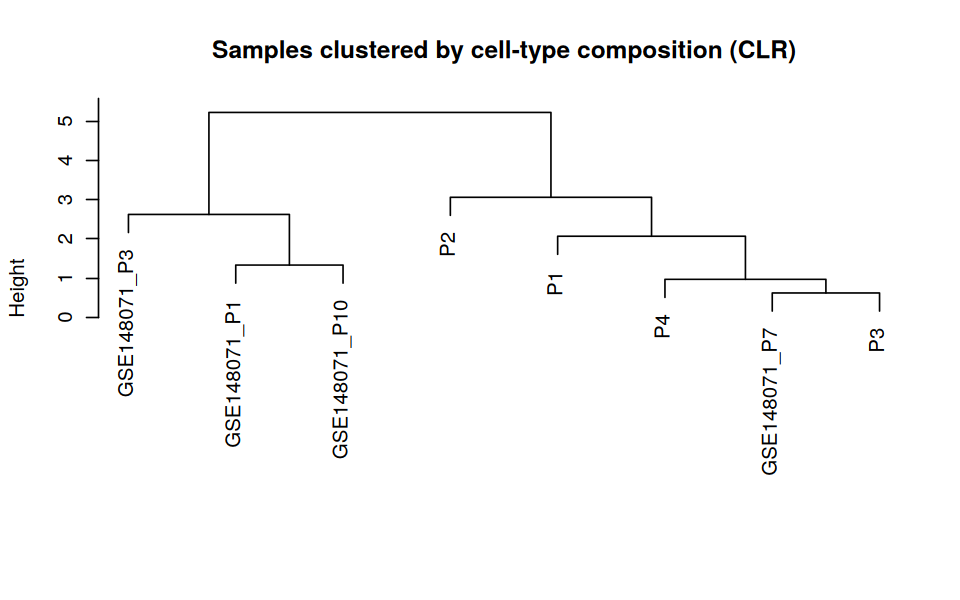

In [4]:
comp <- unclass(table(as.character(nsclc$sample), nsclc$cell_type))
comp <- comp[, colSums(comp >= 10) >= nrow(comp) / 2]      # cell types with >= 10 cells in at least half of the samples
colnames(comp)
clr  <- log(comp + 1) - rowMeans(log(comp + 1))             # centred log-ratio of the proportions (pseudocount 1)

hc <- hclust(dist(clr), method = "average")
options(repr.plot.width = 8, repr.plot.height = 5)
plot(hc, main = "Samples clustered by cell-type composition (CLR)", xlab = "", sub = "")
sample_info$comp_cluster <- factor(paste0("C", cutree(hc, k = 2)[rownames(sample_info)]))
table(infiltration = sample_info$infiltration, composition = sample_info$comp_cluster)
options(repr.plot.width = 12, repr.plot.height = 6)

> **Discussion (composition clusters).** In the log-count heatmap of `integration_annotation.ipynb`, P2 splits off first (its own "Neurons" cluster), then {P1, P3, P4, GSE148071_P7} separate from {GSE148071_P1, P3, P10}. These are exactly the **high** and **low** infiltration samples: the two macro clusters are driven by the immune-to-epithelial ratio (T cells, B cells and myeloid cells vs epithelial cells and fibroblasts). The CLR clustering above should give the same split with P2 joining the immune-rich group; the table shows whether it does.
>
> **So yes, you can use them as groups**, with the same caveats as for infiltration (they are the same split): confounded with the study, and the effect is estimated from GSE148071_P7 vs GSE148071_P1/P3/P10. A clustering of 8 samples is also unstable: one sample more or less can move the cut. If the two groupings differ, replace `infiltration` with `comp_cluster` in the design of section C3. The immune fraction has the advantage of an explicit, interpretable definition.

> **Discussion.** With the cell-type counts of our previous annotation run, the immune fractions are roughly: **GSE148071_P3 2%, GSE148071_P10 13%, GSE148071_P1 19%** (low); **P2 45%, P1 58%, P4 84%, P3 88%, GSE148071_P7 90%** (high, P2 just below the cut). The cut at 0.5 falls in the gap between 19% and 45%. The *PTPRC*+ fraction should rank the samples in the same order; if it does not, the class depends on the annotation and should not be trusted.
>
> **Can we use infiltration as a class? Yes, as a demonstration, with three caveats:**
> 1. **It is confounded with the study.** All four NSCLC_7pt samples are "high"; every "low" sample is from GSE148071. Without `dataset` in the model, "high vs low" would just repeat "NSCLC_7pt vs GSE148071". With `~ dataset + infiltration`, the infiltration effect is estimated **only within GSE148071**: P7 against P1, P3 and P10 (1 vs 3 donors). The NSCLC_7pt samples still help estimate the gene-wise dispersion.
> 2. **The composition of a dissociated sample is not the composition of the tumour.** Dissociation, cell viability and sampling (biopsy vs resection) change the fraction of immune cells. Histology (CD8/CD45 staining) or bulk deconvolution are the usual references.
> 3. **A cut-off on a continuous value loses information.** A continuous covariate is the alternative: `design = ~ dataset + immune_frac` (scaled), which also uses the 58–88% spread within NSCLC_7pt.

## B. Epithelial pseudobulk profiles

For each sample, the **raw counts of its epithelial cells are summed** (sums are still counts, as DESeq2 expects). A sparse indicator matrix (cells × samples) does this in one matrix product. P2 has very few epithelial cells (most of its non-immune cells are the P2-only "Neurons"/"iPS_cells" clusters), so its pseudobulk will fail the size filter.

In [5]:
stage_times["B. Epithelial pseudobulk"] <- Sys.time()
keep <- nsclc$cell_type == epi_label
stopifnot(any(keep))                                   # the label must exist

group  <- droplevels(factor(nsclc$sample[keep]))
counts <- LayerData(nsclc, layer = "counts")[, keep]
pb_epi <- as.matrix(counts %*% Matrix::t(Matrix::fac2sparse(group)))
storage.mode(pb_epi) <- "integer"
dim(pb_epi)                                            # genes x samples

pb_info <- data.frame(
  sample_info[colnames(pb_epi), c("sample", "dataset", "infiltration", "immune_frac")],
  n_cells  = as.vector(table(group)[colnames(pb_epi)]),
  lib_size = colSums(pb_epi),
  n_genes  = colSums(pb_epi > 0)
)
pb_info$pass <- pb_info$n_cells >= min_cells & pb_info$lib_size >= min_lib
pb_info

[1] 22777     8

,sample,dataset,infiltration,immune_frac,n_cells,lib_size,n_genes,pass
,<chr>,<chr>,<fct>,<dbl>,<int>,<dbl>,<dbl>,<lgl>
P1,P1,NSCLC_7pt,high,0.580,522,11149345,20263,TRUE
P2,P2,NSCLC_7pt,low,0.450,6,42313,5733,FALSE
P3,P3,NSCLC_7pt,high,0.878,85,1125471,15715,TRUE
P4,P4,NSCLC_7pt,high,0.837,120,2088928,17598,TRUE
GSE148071_P1,GSE148071_P1,GSE148071,low,0.186,3672,28947908,17960,TRUE
GSE148071_P3,GSE148071_P3,GSE148071,low,0.015,7175,34900334,17515,TRUE
GSE148071_P7,GSE148071_P7,GSE148071,high,0.899,230,1553357,14302,TRUE
GSE148071_P10,GSE148071_P10,GSE148071,low,0.128,2505,18938037,18358,TRUE


## C. Pseudobulk QC

The recommended checks before a pseudobulk DE test (OSCA *Multi-sample comparisons*; DESeq2 and edgeR vignettes):

| Check | Why |
|---|---|
| cells and counts per pseudobulk | a pseudobulk of a few cells is noisy and gets too much weight |
| gene filtering (`filterByExpr`) | genes with too few counts cannot be tested and only add to the multiple-testing burden |
| normalisation factors (TMM / size factors) | must be moderate; extreme values point to a different composition |
| MDS / PCA and sample correlations | outliers, and whether batch or class drives the main variation |
| covariates of the main PCs | which known variable (dataset, class, size) explains the main variation |
| ambient RNA in epithelial pseudobulks | immune transcripts in the soup can look like "up in high infiltration" |

### C1. Size of each pseudobulk

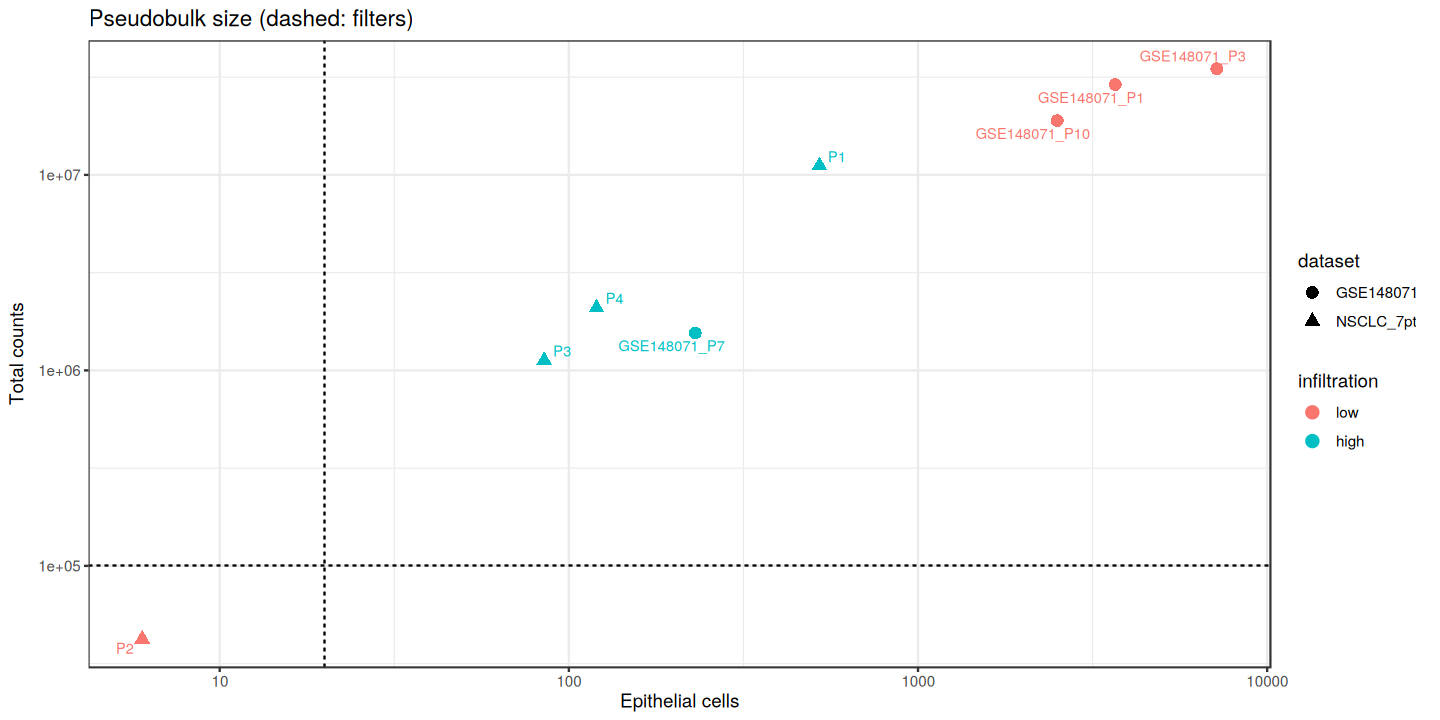

In [6]:
stage_times["C. Pseudobulk QC"] <- Sys.time()
print(ggplot(pb_info, aes(n_cells, lib_size, colour = infiltration, shape = dataset, label = sample)) +
        geom_point(size = 3) + ggrepel::geom_text_repel(size = 3, show.legend = FALSE) +
        geom_vline(xintercept = min_cells, linetype = 2) + geom_hline(yintercept = min_lib, linetype = 2) +
        scale_x_log10() + scale_y_log10() + theme_bw() +
        labs(x = "Epithelial cells", y = "Total counts", title = "Pseudobulk size (dashed: filters)"))

### C2. MDS of all epithelial pseudobulks (before the size filter)

Warning message in filterByExpr.DGEList(y):
“All samples appear to belong to the same group.”


,lib.size,norm.factors
,<dbl>,<dbl>
P1,9477546,0.9379008
P2,40889,1.0509937
P3,891390,1.0051628
P4,1588922,1.1032977
GSE148071_P1,23319605,1.0269589
GSE148071_P3,29043182,0.9768600
GSE148071_P7,1194448,1.0290083
GSE148071_P10,16145767,0.8861549


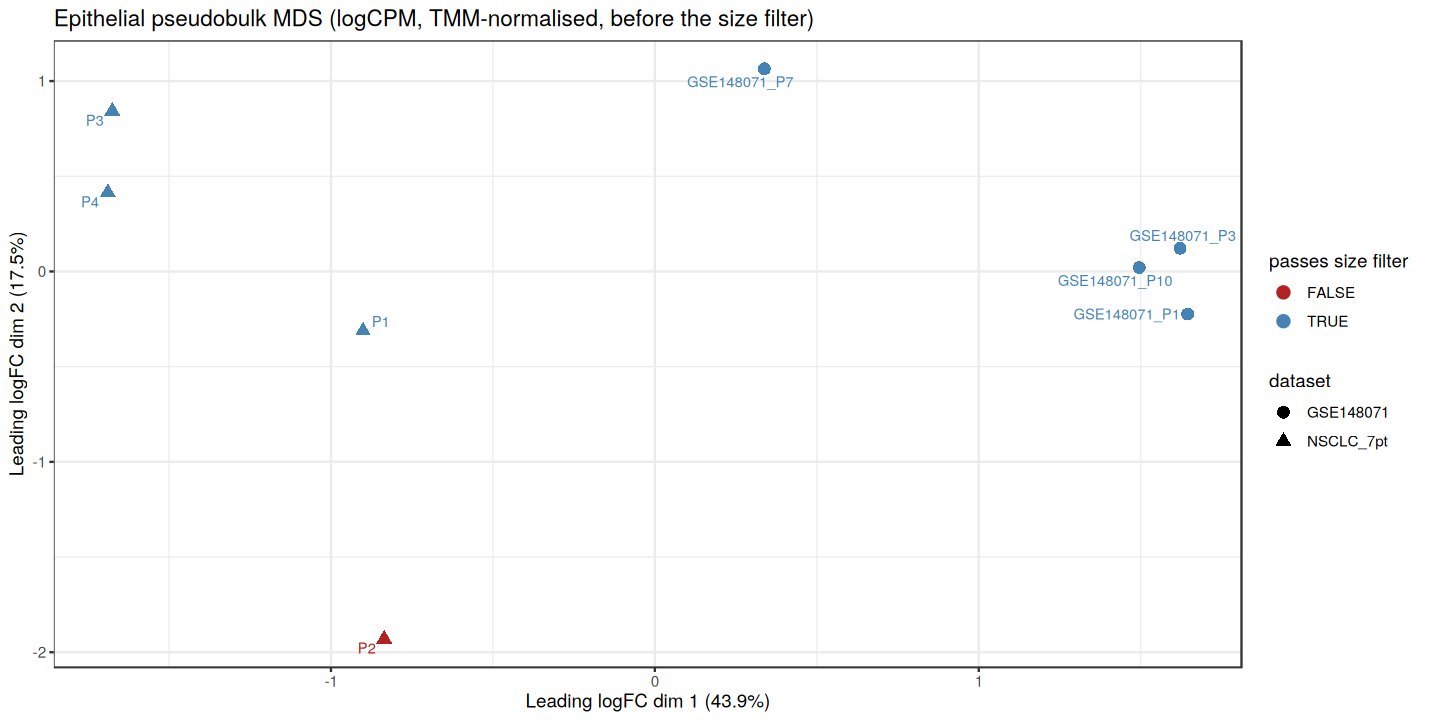

In [7]:
# All epithelial pseudobulks, no min_cells filter
y <- edgeR::DGEList(counts = pb_epi, samples = pb_info)
y <- y[edgeR::filterByExpr(y), , keep.lib.sizes = FALSE]   # drop uninformative genes only
y <- edgeR::calcNormFactors(y)                              # TMM, so MDS isn't driven by library size
y$samples[, c("lib.size", "norm.factors")]                  # norm factors far from 1 = unusual composition

mds <- limma::plotMDS(y, plot = FALSE)                      # log-CPM, top 500 genes, pairwise
var_exp <- round(100 * mds$var.explained[1:2], 1)

mds_df <- data.frame(
  sample           = pb_info$sample,
  dim1             = mds$x,
  dim2             = mds$y,
  dataset          = pb_info$dataset,
  infiltration     = pb_info$infiltration,
  passes_min_cells = pb_info$pass
)

print(ggplot(mds_df, aes(dim1, dim2, colour = passes_min_cells, shape = dataset, label = sample)) +
        geom_point(size = 3) +
        ggrepel::geom_text_repel(size = 3, show.legend = FALSE, max.overlaps = Inf) +
        scale_colour_manual(values = c(`TRUE` = "steelblue", `FALSE` = "firebrick"),
                            name = "passes size filter") +
        theme_bw() +
        labs(title = "Epithelial pseudobulk MDS (logCPM, TMM-normalised, before the size filter)",
             x = paste0("Leading logFC dim 1 (", var_exp[1], "%)"),
             y = paste0("Leading logFC dim 2 (", var_exp[2], "%)")))

> **Discussion.** Batch effects are very clearly seen: dimension 1 separates the two datasets. P2 is an outlier, far from every other sample, because its pseudobulk is made of only a handful of cells. P1 has many more epithelial cells than the others, so its library is much larger; that is why the profiles are normalised (TMM) before they are compared.

### C3. Filter pseudobulks and genes, then normalise

Only pseudobulks that pass the size filter are kept. `filterByExpr` keeps genes with enough counts (≥ 10, scaled to CPM) in at least as many samples as the smaller class, so a gene expressed only in the "low" group can still be tested. The design check (`table`) must have samples in every level of both variables.

In [8]:
pb   <- pb_epi[, pb_info$pass]
info <- droplevels(pb_info[pb_info$pass, ])
info$dataset <- factor(info$dataset, levels = c("NSCLC_7pt", "GSE148071"))
c(pseudobulks = ncol(pb_epi), used = ncol(pb))
table(info$dataset, info$infiltration)                        # design check

genes_keep <- edgeR::filterByExpr(pb, group = info$infiltration, min.count = 10)
c(genes_before = nrow(pb), genes_tested = sum(genes_keep))

dds <- DESeq2::DESeqDataSetFromMatrix(pb[genes_keep, ], colData = info, design = ~ dataset + infiltration)
dds <- DESeq2::estimateSizeFactors(dds)
data.frame(sample = colnames(dds), lib_size = info$lib_size, size_factor = round(DESeq2::sizeFactors(dds), 2))

pseudobulks        used 
          8           7

           
            low high
  NSCLC_7pt   0    3
  GSE148071   3    1

genes_before genes_tested 
       22777        14910

,sample,lib_size,size_factor
,<chr>,<dbl>,<dbl>
P1,P1,11149345,1.60
P3,P3,1125471,0.18
P4,P4,2088928,0.37
GSE148071_P1,GSE148071_P1,28947908,3.99
GSE148071_P3,GSE148071_P3,34900334,4.92
GSE148071_P7,GSE148071_P7,1553357,0.23
GSE148071_P10,GSE148071_P10,18938037,2.36


### C4. Variance-stabilised counts: mean–SD, PCA and sample correlations

`vst(blind = TRUE)` ignores the design, so the QC is not biased toward the classes. After VST the SD should be roughly flat along the mean.

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”
using ntop=500 top features by variance



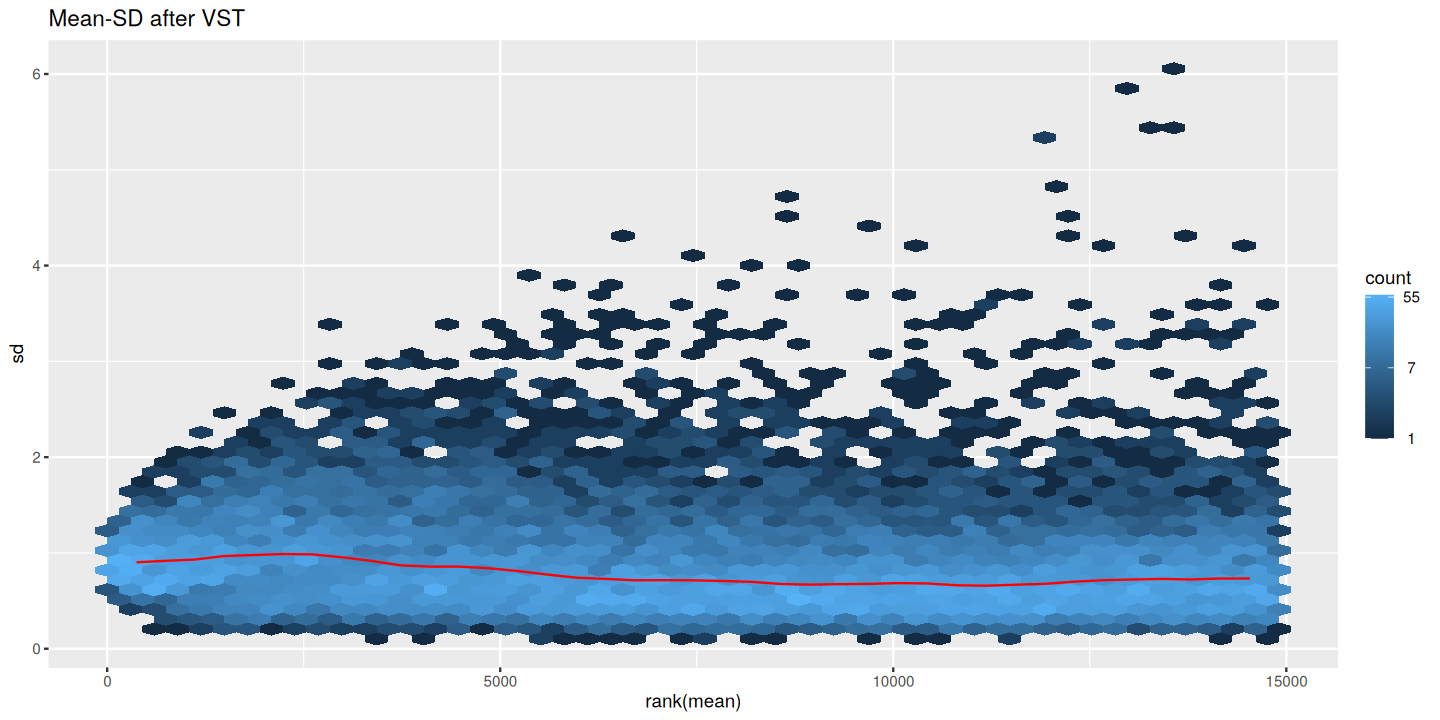

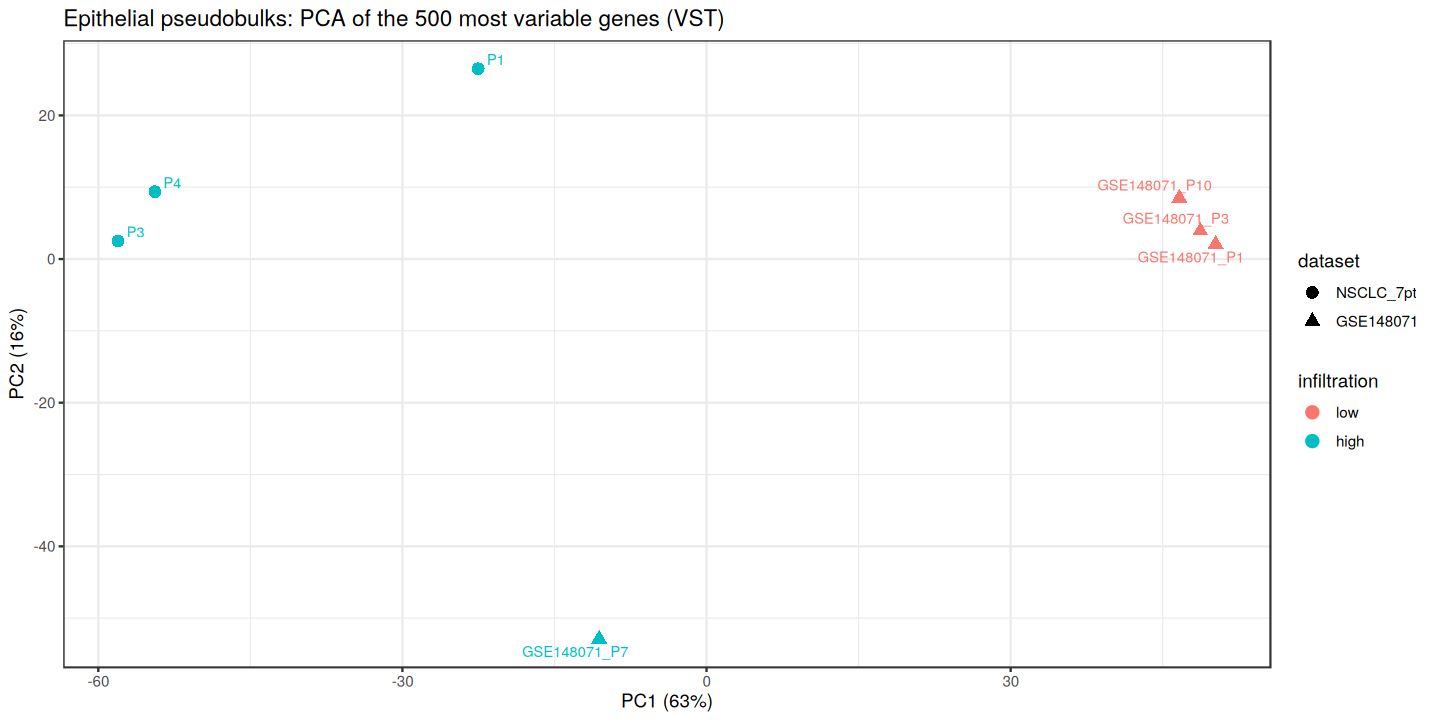

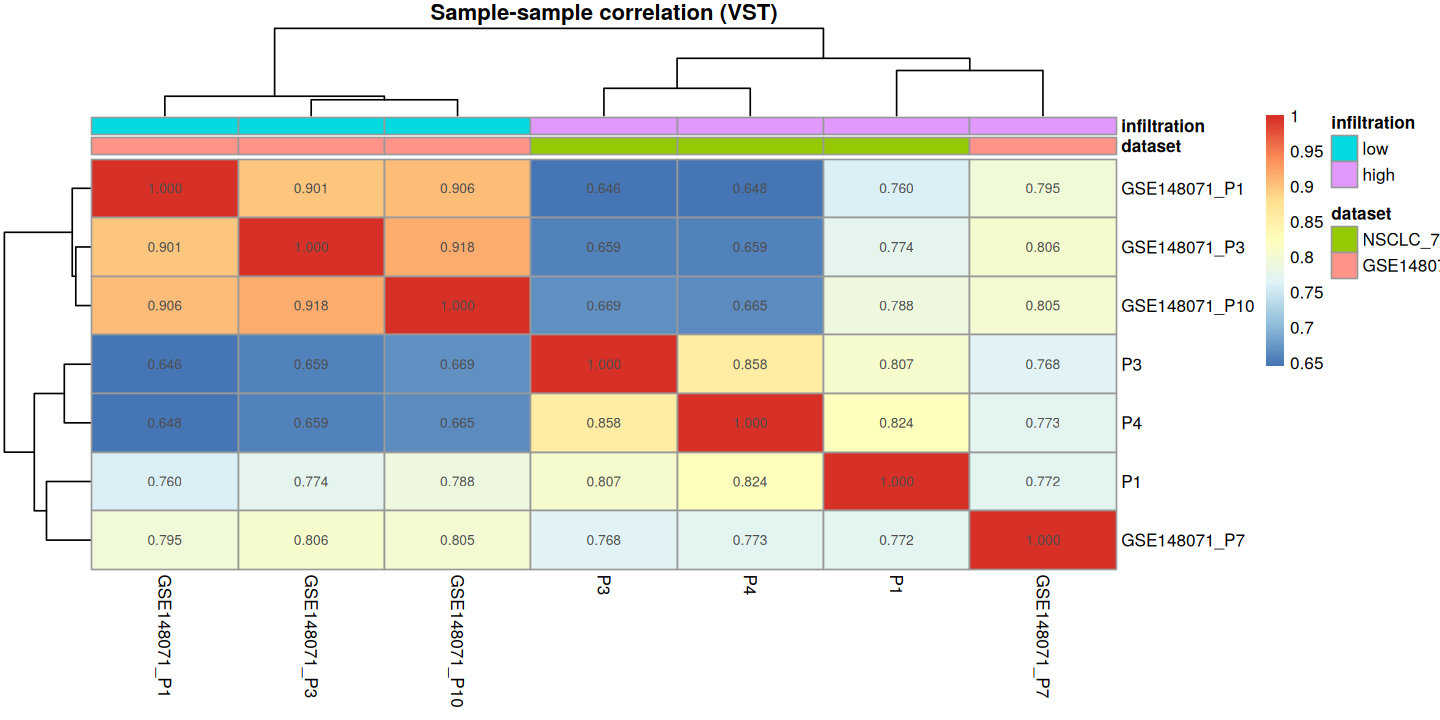

In [9]:
vsd     <- DESeq2::vst(dds, blind = TRUE)
vst_mat <- SummarizedExperiment::assay(vsd)                  # genes x samples, log2-like scale
print(vsn::meanSdPlot(vst_mat, plot = FALSE)$gg + ggtitle("Mean-SD after VST"))

pca <- DESeq2::plotPCA(vsd, intgroup = c("dataset", "infiltration"), returnData = TRUE)
pv  <- round(100 * attr(pca, "percentVar"))
print(ggplot(pca, aes(PC1, PC2, colour = infiltration, shape = dataset, label = name)) +
        geom_point(size = 3) + ggrepel::geom_text_repel(size = 3, show.legend = FALSE) + theme_bw() +
        labs(x = paste0("PC1 (", pv[1], "%)"), y = paste0("PC2 (", pv[2], "%)"),
             title = "Epithelial pseudobulks: PCA of the 500 most variable genes (VST)"))

pheatmap::pheatmap(cor(vst_mat), annotation_col = info[, c("dataset", "infiltration")],
                   display_numbers = TRUE, number_format = "%.3f", main = "Sample-sample correlation (VST)")

### C5. Which known variable explains the main PCs?

R² of each of the first PCs regressed on each covariate. With 7 samples, a single covariate easily reaches a high R² by chance, so look for the **largest** values, not small differences.

In [10]:
top_var <- head(order(apply(vst_mat, 1, var), decreasing = TRUE), 500)
pcs     <- prcomp(t(vst_mat[top_var, ]))$x[, 1:3]
covars  <- data.frame(dataset = info$dataset, infiltration = info$infiltration,
                      log10_cells = log10(info$n_cells), log10_counts = log10(info$lib_size))
round(sapply(covars, function(v) apply(pcs, 2, function(p) summary(lm(p ~ v))$r.squared)), 2)

,dataset,infiltration,log10_cells,log10_counts
PC1,0.76,0.88,0.93,0.77
PC2,0.23,0.03,0.04,0.19
PC3,0.00,0.07,0.00,0.02


### C6. Ambient RNA: immune transcripts in epithelial pseudobulks

We did not correct for ambient RNA (only the SoupX check in `preprocess_preInt`). Epithelial droplets of an immune-rich sample pick up immune transcripts from the soup. If immune genes rise with the immune fraction in **epithelial** pseudobulks, the DE test will report them as "up in high infiltration" even though tumour cells do not express them.

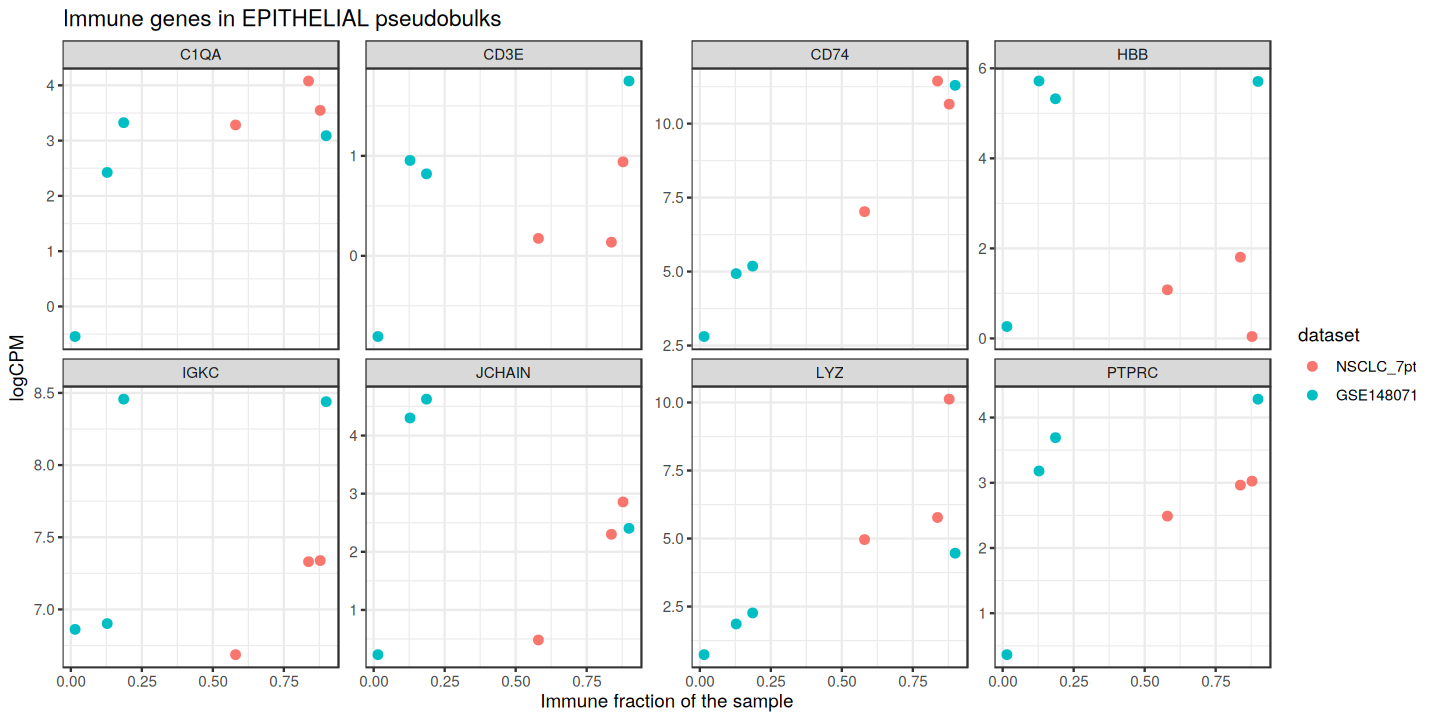

In [11]:
amb_genes <- intersect(c("PTPRC", "CD3E", "CD74", "IGKC", "JCHAIN", "LYZ", "C1QA", "HBB"), rownames(pb))
logcpm    <- edgeR::cpm(pb, log = TRUE)
amb <- data.frame(gene        = rep(amb_genes, times = ncol(pb)),
                  sample      = rep(colnames(pb), each = length(amb_genes)),
                  logCPM      = as.vector(logcpm[amb_genes, ]),
                  immune_frac = rep(info$immune_frac, each = length(amb_genes)),
                  dataset     = rep(info$dataset, each = length(amb_genes)))
print(ggplot(amb, aes(immune_frac, logCPM, colour = dataset)) + geom_point(size = 2) +
        facet_wrap(~ gene, scales = "free_y", nrow = 2) + theme_bw() +
        labs(x = "Immune fraction of the sample", title = "Immune genes in EPITHELIAL pseudobulks"))

> **Discussion (QC).** What to look for before trusting the DE result:
> - **Size:** about 7 pseudobulks should pass (P2 fails). GSE148071_P7 is the only GSE148071 "high" sample and has the fewest epithelial cells of the GSE148071 samples (~230), so the infiltration effect leans on one modest pseudobulk.
> - **Normalisation:** TMM factors and size factors should be within roughly 0.5–2. A sample far outside this range has a different composition (e.g. a different mix of epithelial subtypes or strong contamination).
> - **PCA/MDS and R²:** expect `dataset` to dominate PC1 (the batch is in the counts; Harmony only corrected the embedding). Infiltration can explain a later PC. If `log10_cells` explains PC1 or PC2, pseudobulk size, not biology, drives the variation.
> - **Correlations:** samples correlate more within a dataset than between datasets. A sample that correlates poorly with every other sample is an outlier to inspect before the test.
> - **Ambient RNA:** a rising trend of *IGKC*, *JCHAIN*, *LYZ*, *C1QA* or *CD3E* with immune fraction is contamination. Section D flags these genes as `ambient_risk`.
> - **Epithelial heterogeneity:** `Epithelial_cells` mixes tumour cells with normal alveolar and airway cells (*SFTPC*, *SFTPB*, *SCGB1A1*). If one class has more normal epithelium, the DE result reflects that composition. Sub-clustering the epithelial cells first gives a cleaner comparison.

## D. DE: epithelial cells of high vs low infiltration tumours

`design = ~ dataset + infiltration`: `dataset` absorbs the study batch and `infiltrationhigh` is the effect of interest. DESeq2 estimates size factors, gene-wise dispersions (shared across genes), fits a negative binomial GLM and tests the coefficient with a Wald test. The log2 fold changes are **shrunk** with `apeglm` so that genes with low counts or high dispersion do not get extreme fold changes.

Each gene also gets an **ambient-risk flag**: genes ≥ 4× more abundant in non-epithelial cells than in epithelial cells of the whole dataset (CPM ratio). A DEG with this flag is likely contamination rather than tumour-cell expression.

In [12]:
stage_times["D. DE epithelial"] <- Sys.time()
dds <- DESeq2::DESeq(dds, parallel = TRUE, quiet = TRUE)
DESeq2::resultsNames(dds)
coef_name <- "infiltration_high_vs_low"

res     <- DESeq2::results(dds, name = coef_name, alpha = fdr)
res_shr <- DESeq2::lfcShrink(dds, coef = coef_name, res = res, type = "apeglm", quiet = TRUE)
summary(res)

# Ambient-risk flag from all cells: CPM in non-epithelial vs epithelial cells
all_counts <- LayerData(nsclc, layer = "counts")
cpm_epi    <- Matrix::rowSums(all_counts[, keep])  / sum(all_counts[, keep])  * 1e6
cpm_rest   <- Matrix::rowSums(all_counts[, !keep]) / sum(all_counts[, !keep]) * 1e6

de <- data.frame(gene          = rownames(res),
                 baseMean      = res$baseMean,
                 log2FC        = res$log2FoldChange,
                 log2FC_shrunk = res_shr$log2FoldChange,
                 pvalue        = res$pvalue,
                 padj          = res$padj,
                 log2_rest_vs_epi = log2((cpm_rest[rownames(res)] + 1) / (cpm_epi[rownames(res)] + 1)))
de$ambient_risk <- de$log2_rest_vs_epi > 2
de$DEG <- !is.na(de$padj) & de$padj < fdr & abs(de$log2FC_shrunk) >= min_lfc
de <- de[order(de$padj), ]
write.csv(de, file.path(table_dir, "DE_epithelial_infiltration_high_vs_low.csv"), row.names = FALSE)

table(direction    = ifelse(de$log2FC_shrunk > 0, "up in high", "down in high")[de$DEG],
      ambient_risk = de$ambient_risk[de$DEG])
head(de[de$DEG & !de$ambient_risk, ], 20)

[1] "Intercept"                      "dataset_GSE148071_vs_NSCLC_7pt"
[3] "infiltration_high_vs_low"


out of 14910 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 312, 2.1%
LFC < 0 (down)     : 89, 0.6%
outliers [1]       : 87, 0.58%
low counts [2]     : 290, 1.9%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



              ambient_risk
direction      FALSE TRUE
  down in high    59    0
  up in high     232   79

,gene,baseMean,log2FC,log2FC_shrunk,pvalue,padj,log2_rest_vs_epi,ambient_risk,DEG
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<lgl>
SFTPB,SFTPB,13535.8532,13.620743,13.420120,1.571602e-31,2.284009e-27,-3.7500934,FALSE,TRUE
SFTPA2,SFTPA2,5387.8674,18.914984,20.556346,1.236324e-30,8.983751e-27,-3.7650610,FALSE,TRUE
SFTPA1,SFTPA1,4667.9612,18.397806,20.004301,2.425941e-27,1.003566e-23,-3.6619418,FALSE,TRUE
KRT7,KRT7,2408.1160,6.472673,6.368037,2.762171e-27,1.003566e-23,-0.5224053,FALSE,TRUE
SCGB3A2,SCGB3A2,8558.6260,13.669145,13.415786,5.547570e-25,1.612457e-21,-4.2854966,FALSE,TRUE
SFTPC,SFTPC,16190.6796,15.149069,14.831364,2.122886e-22,5.141984e-19,-4.1755648,FALSE,TRUE
HP,HP,120.0517,13.936977,15.135452,4.965840e-20,1.030979e-16,0.4053124,FALSE,TRUE
SCGB1A1,SCGB1A1,11619.2387,15.952417,17.485926,3.014239e-19,5.475742e-16,-4.5875042,FALSE,TRUE
C3,C3,612.1338,7.616778,7.413244,1.091924e-17,1.763215e-14,1.1416651,FALSE,TRUE


### D1. Checks after the fit

| Plot | Expected |
|---|---|
| dispersion estimates | gene-wise estimates (black) scatter around the fitted trend (red), which falls with the mean |
| p-value histogram | flat, with a peak near 0 if there is signal. A U-shape or a peak near 1 points to a mis-specified model or a hidden covariate |
| MA plot | DEGs on both sides, no trend of fold change with mean |
| Cook's distance | similar per sample. One sample with much higher values is driving many genes on its own |

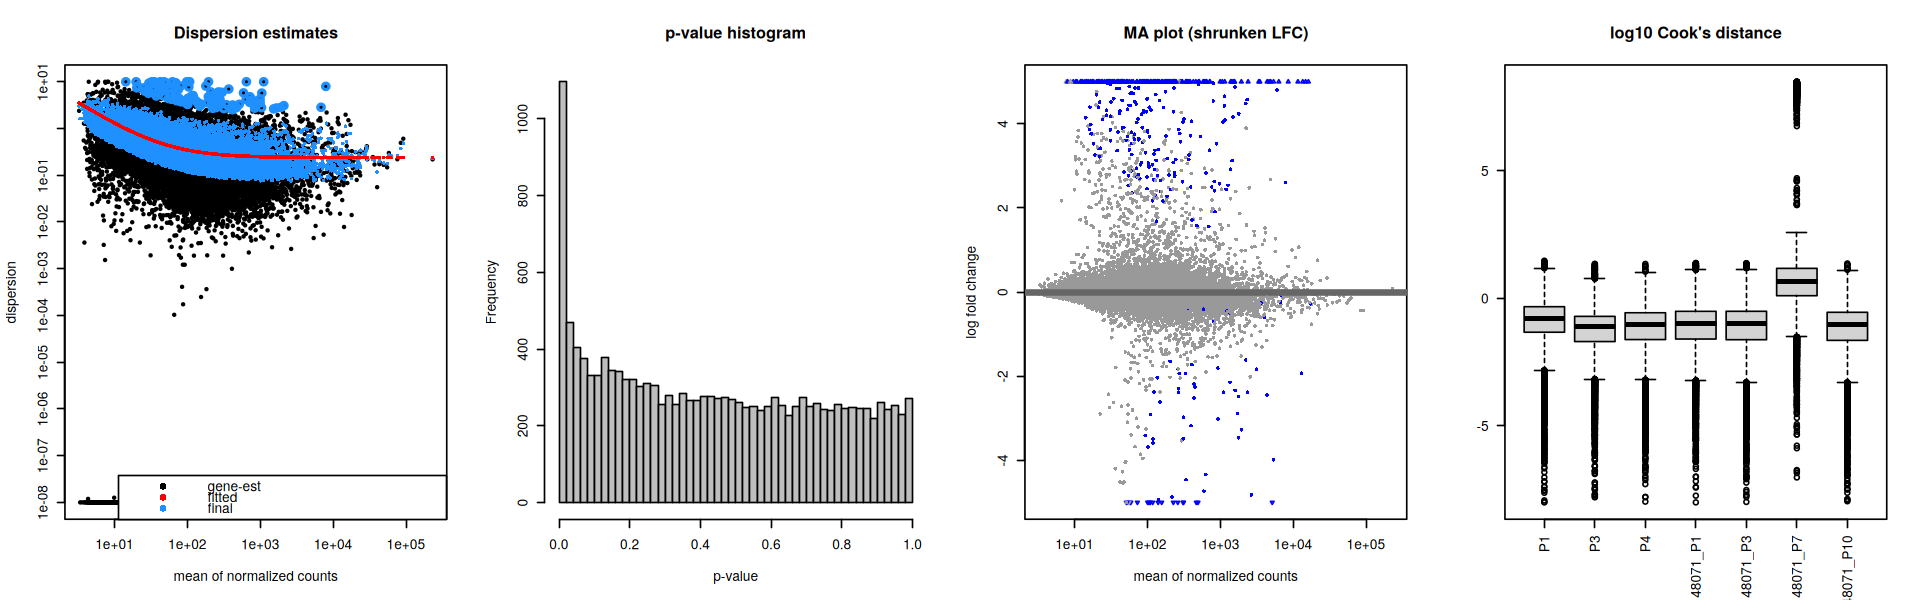

In [13]:
options(repr.plot.width = 16, repr.plot.height = 5)
par(mfrow = c(1, 4))
DESeq2::plotDispEsts(dds, main = "Dispersion estimates")
hist(res$pvalue[res$baseMean > 1], breaks = 40, col = "grey", main = "p-value histogram", xlab = "p-value")
DESeq2::plotMA(res_shr, ylim = c(-5, 5), main = "MA plot (shrunken LFC)")
boxplot(log10(SummarizedExperiment::assays(dds)[["cooks"]] + 1e-8), las = 2, main = "log10 Cook's distance")
par(mfrow = c(1, 1))

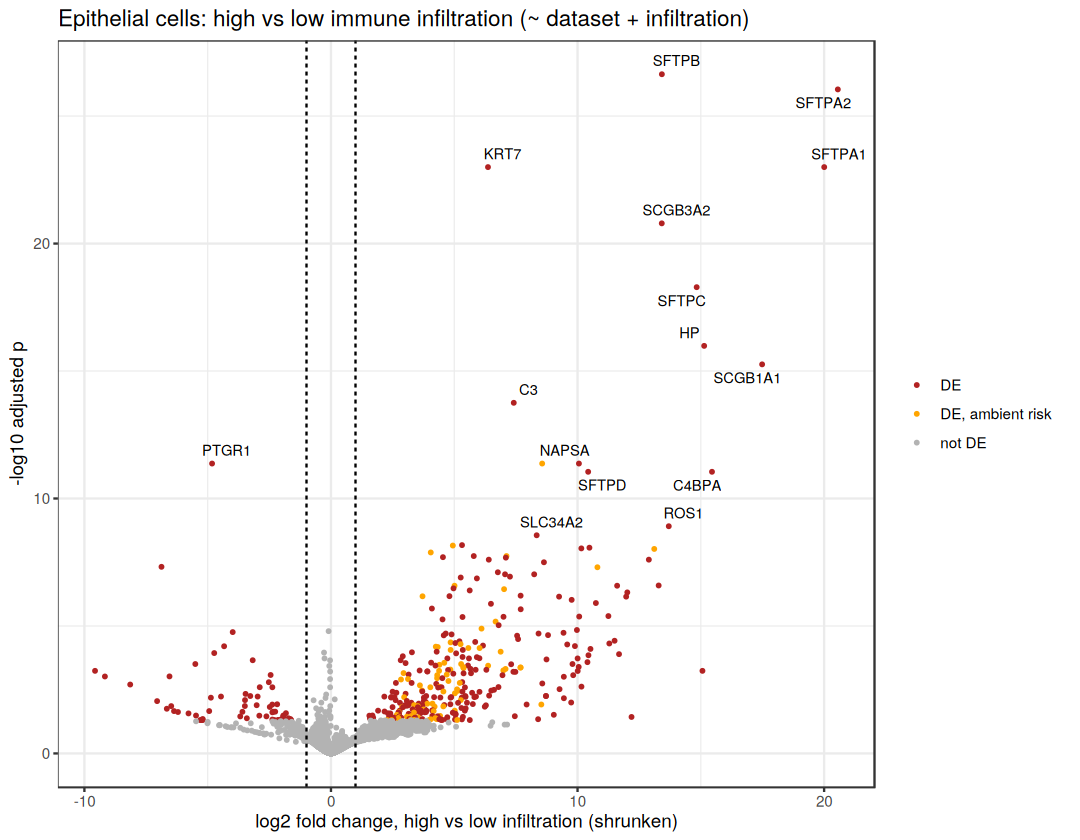

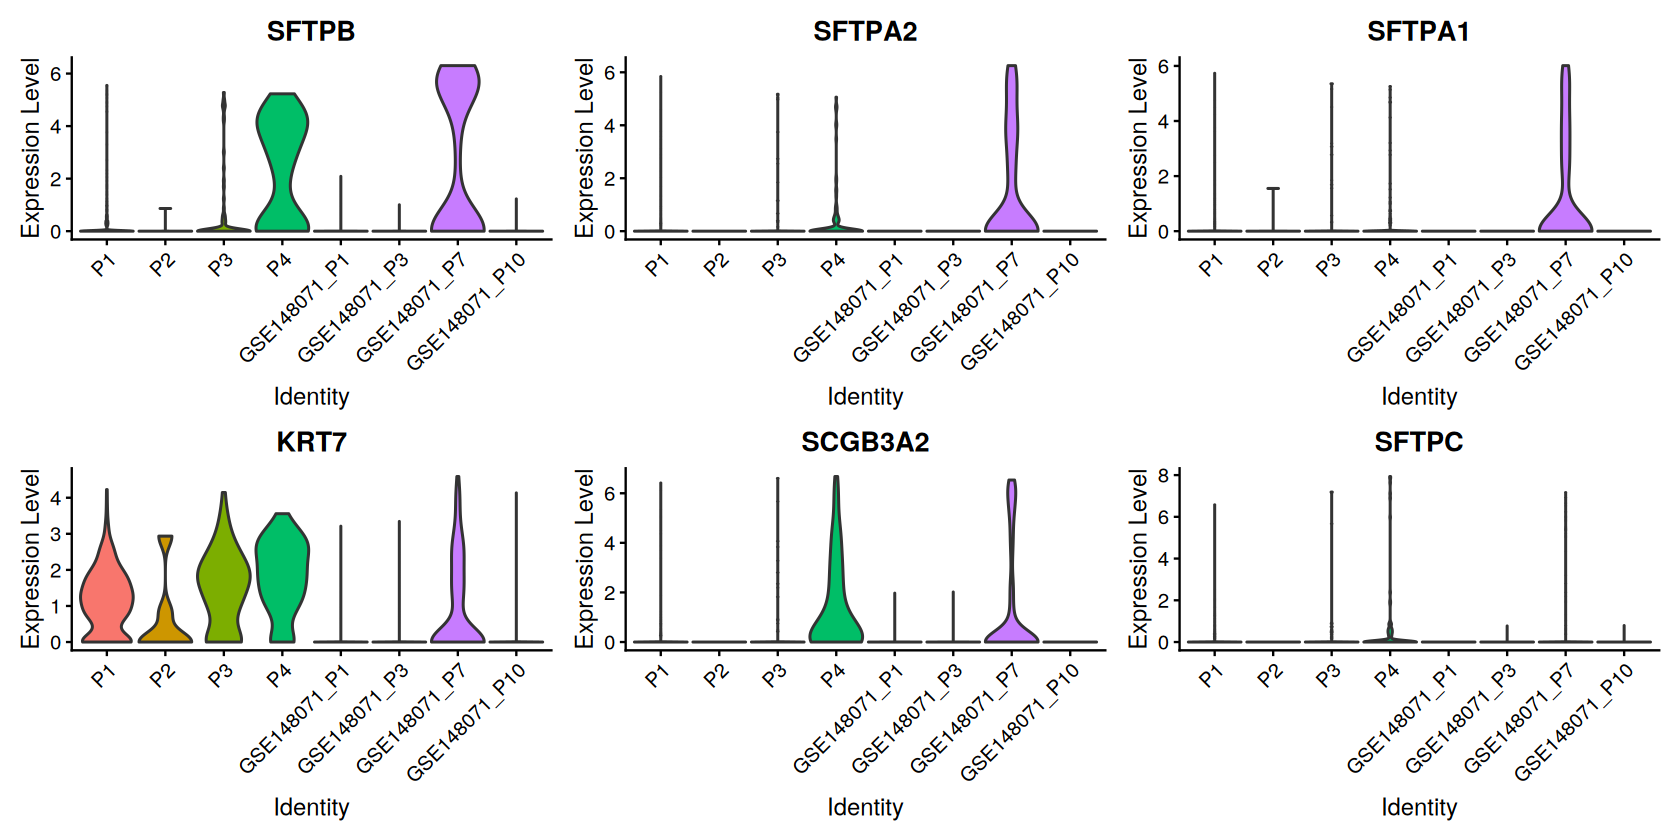

In [14]:
options(repr.plot.width = 9, repr.plot.height = 7)
de_plot <- de[!is.na(de$padj), ]
de_plot$class <- ifelse(!de_plot$DEG, "not DE", ifelse(de_plot$ambient_risk, "DE, ambient risk", "DE"))
print(ggplot(de_plot, aes(log2FC_shrunk, -log10(padj), colour = class)) + geom_point(size = 0.6) +
        scale_colour_manual(values = c(`not DE` = "grey70", DE = "firebrick", `DE, ambient risk` = "orange"), name = NULL) +
        ggrepel::geom_text_repel(data = head(de_plot[de_plot$DEG & !de_plot$ambient_risk, ], 15),
                                 aes(label = gene), colour = "black", size = 3, max.overlaps = Inf) +
        geom_vline(xintercept = c(-min_lfc, min_lfc), linetype = 2) + theme_bw() +
        labs(x = "log2 fold change, high vs low infiltration (shrunken)", y = "-log10 adjusted p",
             title = "Epithelial cells: high vs low immune infiltration (~ dataset + infiltration)"))

# Check the top genes in the single cells: is the change seen in every sample of a class, or driven by one?
top_genes <- head(de$gene[de$DEG & !de$ambient_risk], 6)
if (length(top_genes) > 0) {
  options(repr.plot.width = 14, repr.plot.height = 7)
  print(VlnPlot(subset(nsclc, cells = colnames(nsclc)[keep]), features = top_genes,
                group.by = "sample", pt.size = 0, ncol = 3))
}

> **Discussion.** How to read the result of this design:
> - **The effect is estimated within GSE148071 only** (P7 vs P1, P3, P10). A DEG means "epithelial cells of P7 differ from those of the other three GSE148071 donors", so the violin plots should show the change in P7 against P1/P3/P10. Treat the gene list as **hypotheses**; a donor-level difference unrelated to infiltration (histology, stage, a driver mutation) produces the same pattern.
> - **Expected biology, if the signal is real:** epithelial cells of immune-rich tumours often show an interferon-γ response: MHC class II (*HLA-DRA*, *CD74*), antigen presentation (*B2M*, *HLA-A/B/C*), *CXCL9/10/11*, *IDO1*, *STAT1*, *GBP1*. Proliferation or EMT genes up in "low" tumours fit an immune-excluded phenotype.
> - **Ambient risk:** immunoglobulin genes (*IGKC*, *IGHG*, *JCHAIN*), *LYZ*, *C1Q*, *CCL5* up in "high" are the soup, not tumour cells. *CD74* and HLA class II are flagged too, but epithelial cells can really express them under IFN-γ; check them in the violin plots.
> - **To make this a real comparison:** more donors per class within one study (≥ 3 per class, ideally in both datasets), clinical classes from the GSE148071 supplementary table (e.g. LUAD vs LUSC) instead of a derived class, or the continuous design `~ dataset + immune_frac`.

## Runtime per stage

Seconds from the start of each stage to the start of the next (meaningful for a run from top to bottom without pauses).

In [15]:
stage_times["End"] <- Sys.time()
data.frame(stage = head(names(stage_times), -1), seconds = round(diff(as.numeric(stage_times)), 1))

stage,seconds
<chr>,<dbl>
Setup,1.5
A. Sample classes,13.4
B. Epithelial pseudobulk,1.5
C. Pseudobulk QC,8.6
D. DE epithelial,19.8


In [16]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/sreeram/miniconda3/envs/seurat_env/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Asia/Calcutta
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] BiocParallel_1.40.0 patchwork_1.3.2     ggplot2_4.0.3      
[4] Seurat_5.5.1        SeuratObject_5.4.0  sp_2.2-3           

loaded via a namespace (and not attached):
  [1] RcppAnnoy_0.0.23            splines_4.4.3              
  [3] later_1.4.8                 pbdZMQ_0.3-14     